# Tugas 1 - Seleksi Fitur dan Nilai k pada Klasifikasi Suara

**Nama:** Agus  
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi/tugas-1)

## Soal 1 - Model kNN male/female

Dataset `voice.csv` memuat 20 karakteristik akustik dan label male/female. Duplikat identik dibuang sebelum split stratified 70:30. Data test disisihkan; seleksi fitur, penskalaan, dan pemilihan k dilakukan pada 5-fold CV data latih.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
np.random.seed(42)
sns.set_theme(style='whitegrid')
print('Kernel:', sys.executable)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import f1_score
data = pd.read_csv('data/voice.csv')
print('Ukuran awal:', data.shape, '| Duplikat:', data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
X, y = data.drop(columns='label'), data['label']
assert X.shape[1] == 20 and X.isna().sum().sum() == 0
display(data.head())
display(y.value_counts())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
assert set(X_train.index).isdisjoint(X_test.index)

Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python
Ukuran awal: (3168, 21) | Duplikat: 2


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


label
male      1583
female    1583
Name: count, dtype: int64

## Soal 2–3 - Percobaan jumlah fitur dan k

`SelectKBest(f_classif)` menilai fitur di dalam setiap fold. Dicoba 3, 5, 8, 10, 15, dan seluruh fitur; k=1,3,…,31. Kombinasi terbaik ditentukan oleh rata-rata akurasi CV, tanpa memakai label test.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipeline = Pipeline([('scaler', StandardScaler()), ('select', SelectKBest(f_classif)),
                     ('knn', KNeighborsClassifier())])
grid = GridSearchCV(pipeline, {'select__k': [3, 5, 8, 10, 15, 'all'],
                              'knn__n_neighbors': list(range(1, 32, 2))},
                    cv=cv, scoring='accuracy', n_jobs=2, return_train_score=True)
grid.fit(X_train, y_train)
results = pd.DataFrame(grid.cv_results_)
results['Fitur'] = results['param_select__k'].astype(str)
display(results[['param_select__k', 'param_knn__n_neighbors', 'mean_train_score',
                 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(15))
print('Parameter terbaik:', grid.best_params_)
print('Akurasi CV:', grid.best_score_)
best = grid.best_estimator_
selected_features = X.columns[best.named_steps['select'].get_support()].tolist()
print('Fitur terpilih:', selected_features)

,param_select__k,param_knn__n_neighbors,mean_train_score,mean_test_score,std_test_score
7,5,3,0.988154,0.979693,0.003777
9,10,3,0.986462,0.979247,0.009604
8,8,3,0.988605,0.978793,0.004170
20,8,7,0.981385,0.978343,0.004626
13,5,5,0.983755,0.977889,0.004814
3,10,1,1.000000,0.977440,0.004716
26,8,9,0.980709,0.977439,0.003175
14,8,5,0.983416,0.976989,0.005395
19,5,7,0.982514,0.976535,0.003664
21,10,7,0.981160,0.976089,0.009830


Parameter terbaik: {'knn__n_neighbors': 3, 'select__k': 5}
Akurasi CV: 0.9796931242755169
Fitur terpilih: ['sd', 'Q25', 'IQR', 'sp.ent', 'meanfun']


## Grafik analisis dan evaluasi satu kali pada test

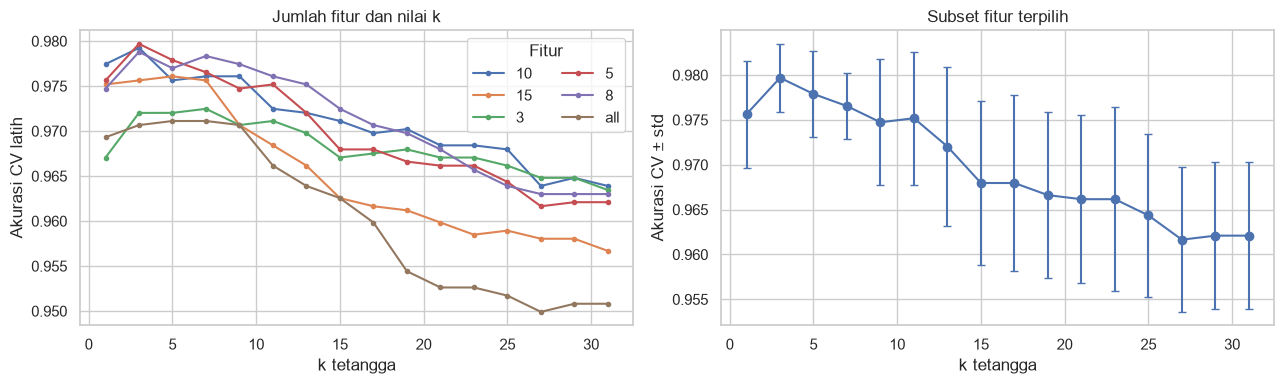

,Model,Akurasi test
0,"Baseline seluruh fitur, k=3",0.972632
1,Pilihan CV,0.978947


              precision    recall  f1-score   support

      female       0.98      0.98      0.98       475
        male       0.98      0.98      0.98       475

    accuracy                           0.98       950
   macro avg       0.98      0.98      0.98       950
weighted avg       0.98      0.98      0.98       950



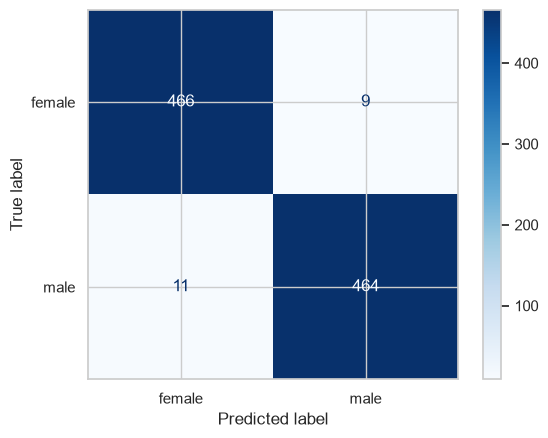

**Jawaban:** fitur terbaik dalam ruang percobaan ini adalah **sd, Q25, IQR, sp.ent, meanfun**. Nilai **k=3** dipilih karena menghasilkan rata-rata akurasi CV tertinggi **0.9797**; akurasi test **0.9789**. Grafik menunjukkan kompromi k kecil yang peka terhadap noise dan k besar yang meratakan batas kelas. Terbaik di sini berlaku untuk kandidat, seed, dan split yang diuji; bukan bukti optimal untuk semua subset fitur.

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for group, rows in results.groupby('Fitur'):
    rows = rows.sort_values('param_knn__n_neighbors')
    axes[0].plot(rows['param_knn__n_neighbors'].astype(int), rows['mean_test_score'], marker='.', label=group)
axes[0].set(xlabel='k tetangga', ylabel='Akurasi CV latih', title='Jumlah fitur dan nilai k')
axes[0].legend(title='Fitur', ncol=2)
best_rows = results[results['Fitur'] == str(grid.best_params_['select__k'])].sort_values('param_knn__n_neighbors')
axes[1].errorbar(best_rows['param_knn__n_neighbors'].astype(int), best_rows['mean_test_score'],
                 yerr=best_rows['std_test_score'], marker='o', capsize=3)
axes[1].set(xlabel='k tetangga', ylabel='Akurasi CV ± std', title='Subset fitur terpilih')
plt.tight_layout()
plt.show()
prediction = best.predict(X_test)
baseline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)).fit(X_train, y_train)
display(pd.DataFrame([
    {'Model': 'Baseline seluruh fitur, k=3', 'Akurasi test': baseline.score(X_test, y_test)},
    {'Model': 'Pilihan CV', 'Akurasi test': accuracy_score(y_test, prediction)}
]))
print(classification_report(y_test, prediction, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, cmap='Blues')
plt.show()
display(Markdown(f'**Jawaban:** fitur terbaik dalam ruang percobaan ini adalah **{", ".join(selected_features)}**. '
                 f'Nilai **k={grid.best_params_["knn__n_neighbors"]}** dipilih karena menghasilkan '
                 f'rata-rata akurasi CV tertinggi **{grid.best_score_:.4f}**; akurasi test **{accuracy_score(y_test, prediction):.4f}**. '
                 'Grafik menunjukkan kompromi k kecil yang peka terhadap noise dan k besar yang meratakan batas kelas. '
                 'Terbaik di sini berlaku untuk kandidat, seed, dan split yang diuji; bukan bukti optimal untuk semua subset fitur.'))